In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.svm import SVC

In [4]:
print(dir(svm))

['LinearSVC', 'LinearSVR', 'NuSVC', 'NuSVR', 'OneClassSVM', 'SVC', 'SVR', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_base', '_bounds', '_classes', '_liblinear', '_libsvm', '_libsvm_sparse', 'l1_min_c']


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,precision_score,accuracy_score

In [4]:
df=pd.read_csv("Social_Network_Ads.csv")

In [5]:
df.head(5)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [6]:
df['Gender']=df['Gender'].map({
    'Male':0,
    'Female':1
})

In [7]:
df=df.drop('User ID',axis=1)

In [12]:
df.head(5)

,Gender,Age,EstimatedSalary,Purchased
0,0,19,19000,0
1,0,35,20000,0
2,1,26,43000,0
3,1,27,57000,0
4,0,19,76000,0


In [8]:
df.columns=df.columns.str.strip()

In [9]:
X=df.drop('Purchased',axis=1)
y=df['Purchased']

In [10]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [11]:
# scaling
scaler=StandardScaler()


In [19]:
df.dtypes

Gender             int64
Age                int64
EstimatedSalary    int64
Purchased          int64
dtype: object

In [12]:
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [13]:
model=SVC(kernel="rbf",C=1.0,random_state=42)

model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [14]:
y_pred=model.predict(x_test)

In [15]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.84375
classification_report :               precision    recall  f1-score   support

           0       0.96      0.90      0.93        51
           1       0.84      0.93      0.89        29

    accuracy                           0.91        80
   macro avg       0.90      0.92      0.91        80
weighted avg       0.92      0.91      0.91        80

 accuracy_score:  0.9125
[[46  5]
 [ 2 27]]


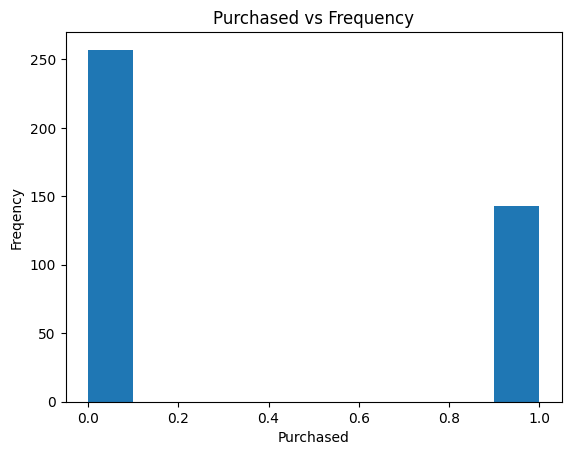

In [36]:
plt.hist(df['Purchased'])
plt.xlabel("Purchased")
plt.ylabel("Freqency")
plt.title("Purchased vs Frequency")
plt.show()

In [48]:
print("hello")

hello


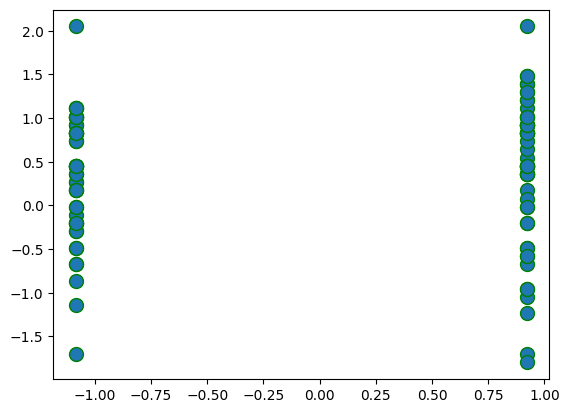

In [40]:
plt.scatter(model.support_vectors_[:,0],model.support_vectors_[:,1],s=100,edgecolors="green")
plt.show()

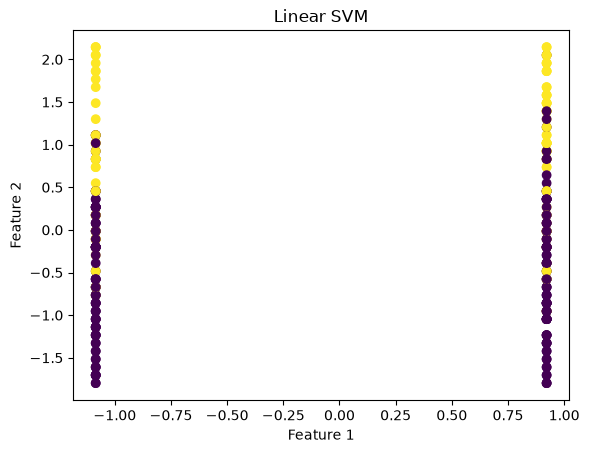

In [17]:
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Linear SVM")

plt.show()

In [18]:
# Admission_Predict.csv

df=pd.read_csv("Admission_Predict.csv")
df.head(5)

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [19]:
df=df.drop('Serial No.',axis=1)

In [20]:
df.isnull().sum()
df.columns=df.columns.str.strip()
df.head(5)

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [21]:
df['Admission Status']=(df['Chance of Admit']>=0.75).astype(int)

In [22]:
X=df.drop(columns=['Admission Status','Chance of Admit'])
y=df['Admission Status']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [23]:
# scaling
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [24]:
model=SVC(kernel="linear",random_state=42)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [25]:
df.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
Admission Status       int64
dtype: object

In [26]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.8378378378378378
classification_report :               precision    recall  f1-score   support

           0       0.95      0.87      0.91        47
           1       0.84      0.94      0.89        33

    accuracy                           0.90        80
   macro avg       0.90      0.91      0.90        80
weighted avg       0.91      0.90      0.90        80

 accuracy_score:  0.9
[[41  6]
 [ 2 31]]


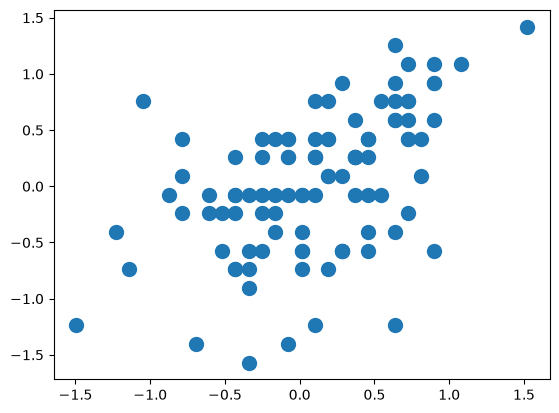

In [32]:
plt.scatter(model.support_vectors_[:,0],model.support_vectors_[:,1],s=100)
plt.show()

In [74]:
# UniversalBank.csv

df=pd.read_csv("UniversalBank.csv")
df.head(5)

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [75]:
df.isnull().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

In [76]:
df.dtypes

ID                      int64
Age                     int64
Experience              int64
Income                  int64
ZIP Code                int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal Loan           int64
Securities Account      int64
CD Account              int64
Online                  int64
CreditCard              int64
dtype: object

In [77]:
df.columns=df.columns.str.strip()
X=df.drop(columns=['ID','ZIP Code','CreditCard'])
y=df['CreditCard']

In [78]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
# scaling
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [80]:
model=SVC(kernel="linear",random_state=42)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [81]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.8548387096774194
classification_report :               precision    recall  f1-score   support

           0       0.75      0.99      0.85       708
           1       0.85      0.18      0.30       292

    accuracy                           0.75      1000
   macro avg       0.80      0.58      0.57      1000
weighted avg       0.78      0.75      0.69      1000

 accuracy_score:  0.752
[[699   9]
 [239  53]]
